<img src="https://www.pucsp.br/sites/default/files/download/brasao-PUCSP-assinatura-principal-RGB.png" style="float:right;" width="150px">

# Ciências da Computação [》](https://www.pucsp.br/graduacao/ciencia-da-computacao)

## Inteligência Artificial

IA ML (Machine Learning, Aprendizagem de Máquina)

**Objetivo deste exercício é explorar os modelos de Bagging e Boosting com Scikit-Learn em Python, sobre os dados de algum conjunto do Vega Dataset**

Inteligência Artificial - ML com Scikit-learn

**Dupla**

| Integrante | Nome | RA |
|---|---|---|
| Integrante 1 | Daniel Teles de Oliveira | RA00334427 |
| Integrante 2 | João Victor Torres Soares | RA00330701 |

# TODO
---

- Implementar um modelo de Boosting
- Implementar um modelo de Bagging
- Usar dados do vega dataset (cada grupo usa um conjunto de dados diferente)
- Implementar com Scikit-Learn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from vega_datasets import data
from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split
from sklearn.ensemble import BaggingRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


# Escolha do conjunto de dados countries
O conjunto de dados reúne informações sobre diferentes países, incluindo indicadores de expectativa de vida e taxa de fertilidade, associados aos respectivos anos de observação.

In [ ]:
df = data.countries()

# Descrição do conjunto
Nesta etapa, realiza-se uma análise da estrutura e da volumetria do conjunto de dados, verificando a quantidade de registros e colunas, as características das variáveis numéricas e a visualização das primeiras amostras. Essa análise inicial permite compreender a organização dos dados e obter uma visão geral do conjunto antes das etapas seguintes do processamento.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 630 entries, 0 to 629
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   _comment       1 non-null      object 
 1   year           630 non-null    int64  
 2   fertility      630 non-null    float64
 3   life_expect    630 non-null    float64
 4   n_fertility    567 non-null    float64
 5   n_life_expect  567 non-null    float64
 6   country        630 non-null    object 
 7   p_fertility    567 non-null    float64
 8   p_life_expect  567 non-null    float64
dtypes: float64(6), int64(1), object(2)
memory usage: 44.4+ KB


In [ ]:
total_registros = len(df)
print(total_registros)

630


In [ ]:
df.describe()

,year,fertility,life_expect,n_fertility,n_life_expect,p_fertility,p_life_expect
count,630.000000,630.000000,630.000000,567.000000,567.000000,567.000000,567.000000
mean,1977.500000,3.731504,65.473222,3.592239,66.342941,3.871930,64.777197
std,14.372818,1.938239,10.631994,1.895985,10.217575,1.949564,10.551816
min,1955.000000,0.940000,23.599000,0.940000,23.599000,1.080000,23.599000
25%,1965.000000,2.072500,59.357250,1.993500,60.180000,2.241000,58.340060
50%,1977.500000,3.106600,68.740000,2.942000,69.610000,3.313000,67.849000
75%,1990.000000,5.361500,73.450750,5.000000,73.825000,5.599800,72.755000
max,2000.000000,8.500000,82.000000,8.500000,82.000000,8.500000,80.690000


# Visualizações de tendências

Nesta etapa, realiza-se uma análise exploratória dos dados por meio de gráficos, com o objetivo de identificar tendências temporais na expectativa de vida e na taxa de fertilidade média, comparar os países com os maiores e menores valores desses indicadores e investigar a relação entre eles por meio de um gráfico de dispersão.

# Evolução da Expectativa de Vida ao Longo dos Anos

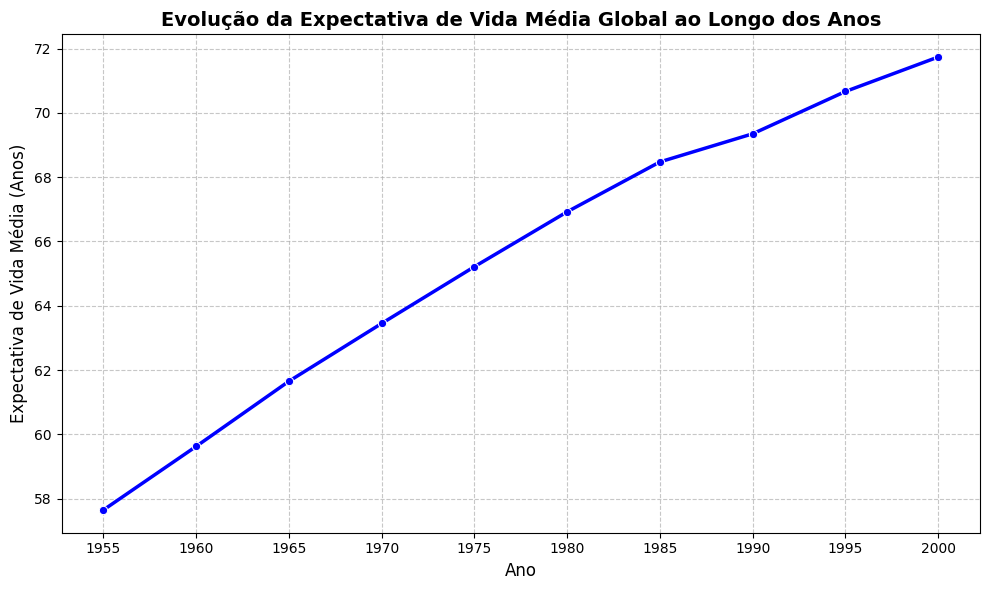

In [31]:
evolucao_vida = df.groupby('year')['life_expect'].mean().reset_index()

plt.figure(figsize=(10, 6))
sns.lineplot(data=evolucao_vida, x='year', y='life_expect', marker='o', color='b', linewidth=2.5)

plt.title('Evolução da Expectativa de Vida Média Global ao Longo dos Anos', fontsize=14, fontweight='bold')
plt.xlabel('Ano', fontsize=12)
plt.ylabel('Expectativa de Vida Média (Anos)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(evolucao_vida['year'].unique())

plt.tight_layout()
plt.show()

# Evolução da Fertilidade ao Longo dos Anos

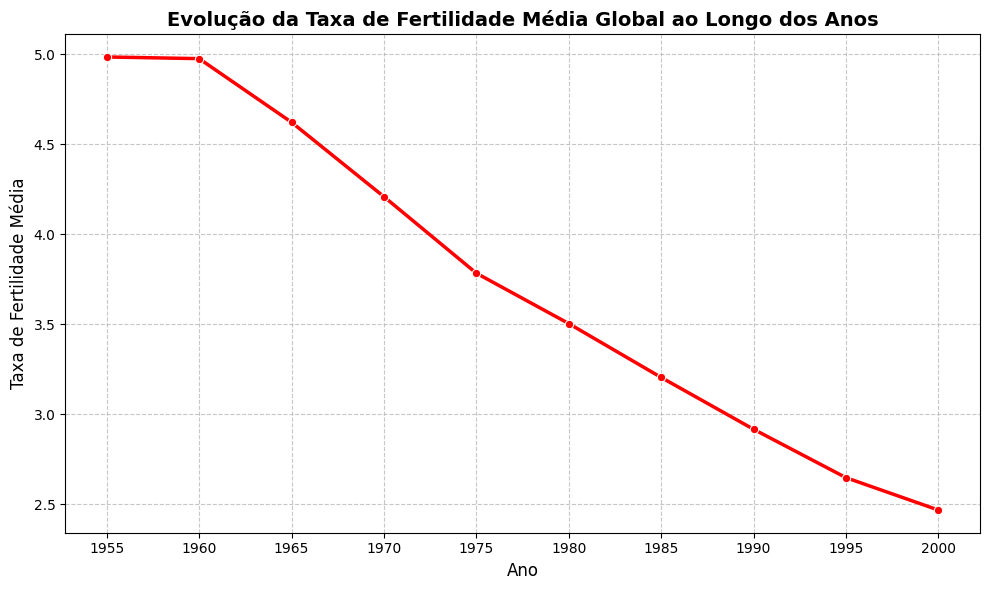

In [32]:
evolucao_fertilidade = df.groupby('year')['fertility'].mean().reset_index()

plt.figure(figsize=(10, 6))
sns.lineplot(data=evolucao_fertilidade, x='year', y='fertility', marker='o', color='r', linewidth=2.5)

plt.title('Evolução da Taxa de Fertilidade Média Global ao Longo dos Anos', fontsize=14, fontweight='bold')
plt.xlabel('Ano', fontsize=12)
plt.ylabel('Taxa de Fertilidade Média', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(evolucao_fertilidade['year'].unique())

plt.tight_layout()
plt.show()

# Comparação dos 5 Países com Maior Expectativa de Vida

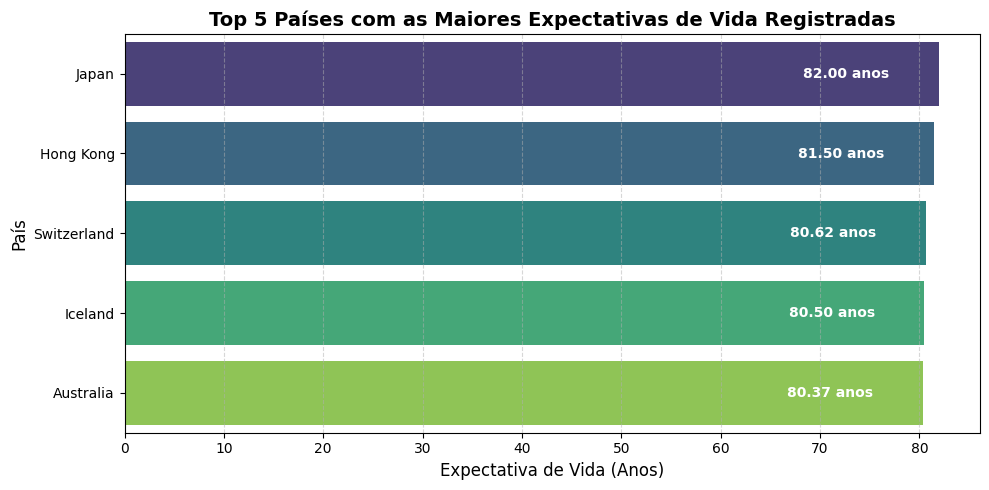

In [29]:
maiores_expectativas = df.groupby('country')['life_expect'].max().nlargest(5).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=maiores_expectativas, x='life_expect', y='country', hue='country', palette='viridis')

plt.title('Top 5 Países com as Maiores Expectativas de Vida Registradas', fontsize=14, fontweight='bold')
plt.xlabel('Expectativa de Vida (Anos)', fontsize=12)
plt.ylabel('País', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5, axis='x')

for index, value in enumerate(maiores_expectativas['life_expect']):
    plt.text(value - 5, index, f'{value:.2f} anos', va='center', ha='right', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

# Comparação dos 5 Países com Maior Taxa de Fertilidade

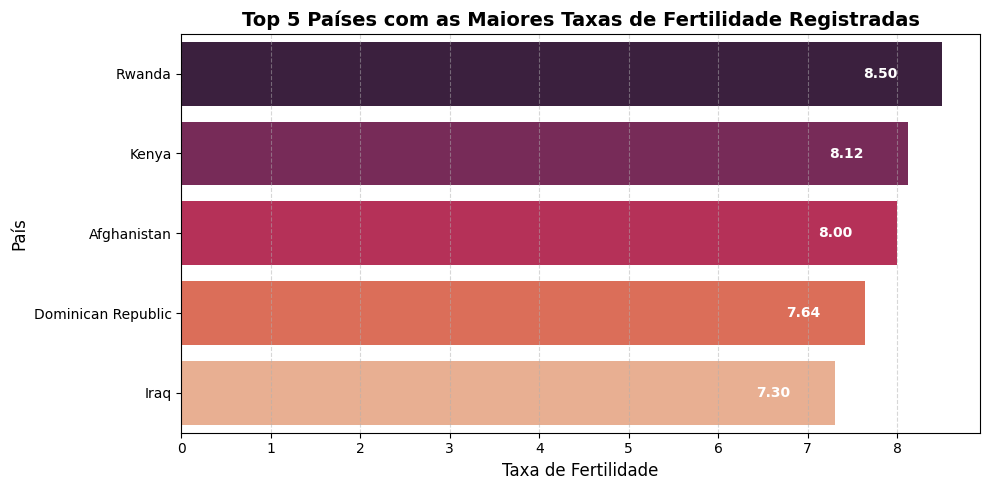

In [30]:
maiores_fertilidades = df.groupby('country')['fertility'].max().nlargest(5).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=maiores_fertilidades, x='fertility', y='country', hue='country', palette='rocket', legend=False)

plt.title('Top 5 Países com as Maiores Taxas de Fertilidade Registradas', fontsize=14, fontweight='bold')
plt.xlabel('Taxa de Fertilidade', fontsize=12)
plt.ylabel('País', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5, axis='x')

for index, value in enumerate(maiores_fertilidades['fertility']):
    plt.text(value - 0.5, index, f'{value:.2f}', va='center', ha='right', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

## Relação entre Fertilidade e Expectativa de Vida

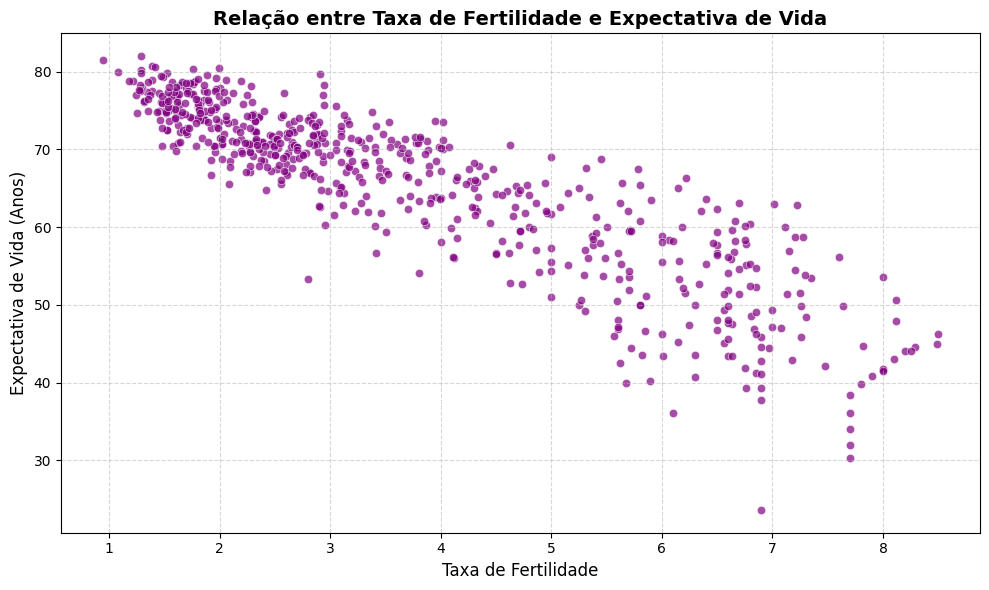

In [23]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='fertility', y='life_expect', alpha=0.7, color='purple')

plt.title('Relação entre Taxa de Fertilidade e Expectativa de Vida', fontsize=14, fontweight='bold')
plt.xlabel('Taxa de Fertilidade', fontsize=12)
plt.ylabel('Expectativa de Vida (Anos)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Verificação de Outliers
---
Nesta etapa, investiga-se a presença de valores extremos nas variáveis numéricas do conjunto de dados, com o objetivo de identificar possíveis inconsistências e observações atípicas que possam influenciar o treinamento e o desempenho dos modelos preditivos. Essa análise permite avaliar a necessidade de manter, corrigir ou tratar esses valores, considerando o contexto e a distribuição de cada variável.

In [22]:
colunas_numericas = df.select_dtypes(include=[np.number]).columns.drop('year', errors='ignore')

outliers_dict = {}

print("=== Detecção de Outliers usando o Intervalo Interquartil (IQR) ===\n")

for col in colunas_numericas:
    # Remove valores nulos temporariamente para o cálculo dos quartis
    col_data = df[col].dropna()

    if len(col_data) == 0:
        continue

    Q1 = col_data.quantile(0.25)
    Q3 = col_data.quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = col_data[(col_data < limite_inferior) | (col_data > limite_superior)]

    outliers_dict[col] = outliers.tolist()

    print(f"Variável: {col}")
    print(f"  Q1: {Q1:.3f} | Q3: {Q3:.3f} | IQR: {IQR:.3f}")
    print(f"  Limites: [{limite_inferior:.3f}, {limite_superior:.3f}]")
    print(f"  Quantidade de Outliers: {len(outliers)}")
    if len(outliers) > 0:
        print(f"  Valores Outliers: {outliers.tolist()[:10]}... (mostrando até 10 valores)" if len(outliers) > 10 else f"  Valores Outliers: {outliers.tolist()}")
    print("-" * 50)

=== Detecção de Outliers usando o Intervalo Interquartil (IQR) ===

Variável: fertility
  Q1: 2.072 | Q3: 5.362 | IQR: 3.289
  Limites: [-2.861, 10.295]
  Quantidade de Outliers: 0
--------------------------------------------------
Variável: life_expect
  Q1: 59.357 | Q3: 73.451 | IQR: 14.093
  Limites: [38.217, 94.591]
  Quantidade de Outliers: 7
  Valores Outliers: [30.332, 31.997, 34.02, 36.088, 37.802, 23.599, 36.087]
--------------------------------------------------
Variável: n_fertility
  Q1: 1.994 | Q3: 5.000 | IQR: 3.006
  Limites: [-2.516, 9.510]
  Quantidade de Outliers: 0
--------------------------------------------------
Variável: n_life_expect
  Q1: 60.180 | Q3: 73.825 | IQR: 13.645
  Limites: [39.713, 94.292]
  Quantidade de Outliers: 7
  Valores Outliers: [31.997, 34.02, 36.088, 38.438, 39.36, 23.599, 36.087]
--------------------------------------------------
Variável: p_fertility
  Q1: 2.241 | Q3: 5.600 | IQR: 3.359
  Limites: [-2.797, 10.638]
  Quantidade de Outliers:

# Justificativa de Preservação dos Outliers Demográficos
---
Foram identificados outliers principalmente nas colunas de expectativa de vida, com valores excepcionalmente baixos.

Porém, essess valores representam fenômenos reais e históricos, não sendo sendo, portanto, algum erro de digitação ou falha de medição.

Se esses valores forem removidos, os modelos aprenderiam apenas cenários ideais ou moderados. Ao manter esses dados, permitimos que o modelo compreenda e preveja cenários de crise e comportamento demográfico sob forte estresse social.

Portanto, esses valores atípicos são fundamentais para garantir a representatividade da desigualdade socioeconômica global na análise.

# Correlação entre variáveis

Nesta etapa, analisam-se as correlações entre as variáveis do conjunto de dados, com o objetivo de identificar a intensidade e a direção das relações entre elas, bem como avaliar quais apresentam maior associação com a variável-alvo e podem contribuir para o desempenho do modelo preditivo.

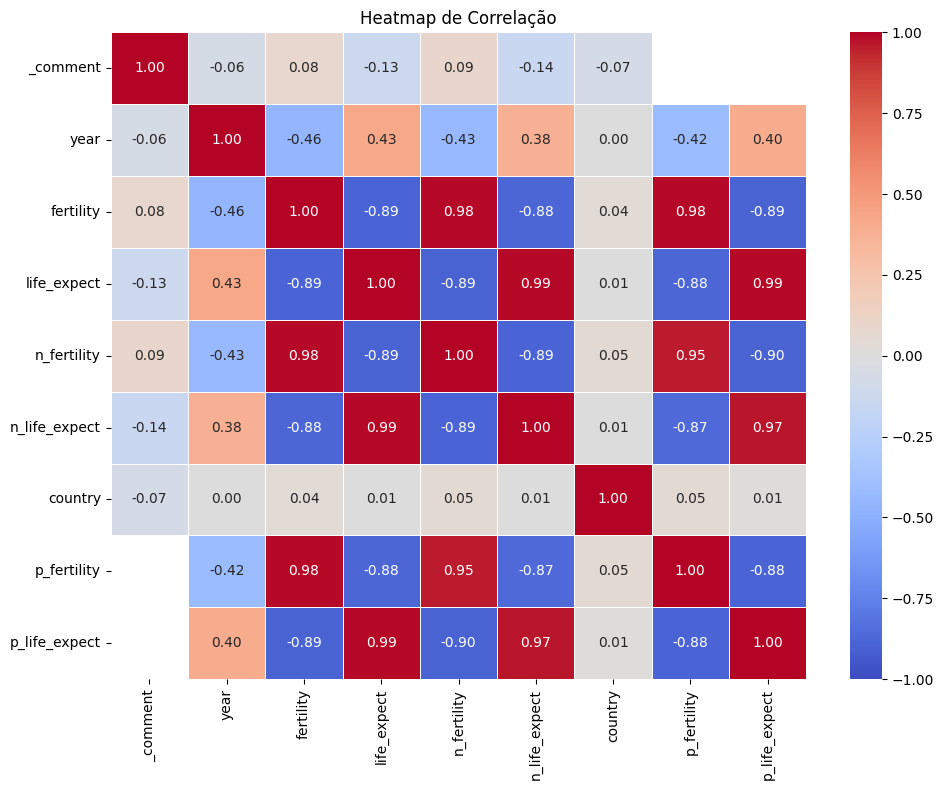

In [ ]:
df_encoded = df.copy()

# Conversão de colunas categóricas/objeto em numéricas
for col in df_encoded.select_dtypes(include=['object']).columns:
    df_encoded[col] = df_encoded[col].astype('category').cat.codes

# Cálculo das correlações
corr_matrix = df_encoded.corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1, vmax=1
)

plt.title('Heatmap de Correlação')
plt.tight_layout()
plt.show()

# Objetivo da regressão

O objetivo da regressão é estimar os valores da expectativa de vida com base nas variáveis disponíveis no conjunto de dados. Variáveis relacionadas ao histórico de expectativas de vida futuras ou passadas são desconsideradas para evitar *data leakage*

Assim, O modelo é treinado com os dados de treino para identificar padrões e relações entre as variáveis, visando prever se a expectativa de vida dos países. Posteriormente, seu desempenho é avaliado com os dados de teste, verificando sua capacidade de generalização para dados não utilizados durante o treinamento.

# Tratamento do conjunto e divisão entre atributos e a variável-alvo
---

Nesta etapa, realiza-se o tratamento do conjunto de dados, inicialmente selecionando as variáveis de interesse e removendo as observações que apresentam valores ausentes. Em seguida, a variável categórica *country* é codificada numericamente, permitindo sua utilização pelos algoritmos de aprendizado de máquina. Posteriormente, são definidos os atributos preditore, compostos pelas variáveis *p_fertility*, *year* e *country*, e a variável-alvo, correspondente à expectativa de vida. Essa organização estrutura os dados para o treinamento e a avaliação dos modelos de regressão.

In [ ]:
df_tratado = df[['year','life_expect', 'fertility', 'n_fertility','n_life_expect', 'p_fertility', 'p_life_expect', 'country']].dropna()
# Codificando a coluna 'country' para que seja representada por valores numéricos
df_tratado['country'] = df_tratado['country'].astype('category').cat.codes

X = df_tratado[['p_fertility', 'year', 'country']]
y = df_tratado['life_expect']

#Divisão dos dados
---
Esta etapa consiste na divisão do modelo em treinamento e teste, utilizando a divisão 80% para treino e 20% para teste

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Modelo de Bagging
---

Nessa etapa, utiliza-se como estimador o modelo de regressão baseado em Árvores de Decisão, associado à técnica de Bagging, um método de aprendizado supervisionado que combina as previsões de múltiplas árvores, treinadas independentemente em diferentes amostras dos dados, com o objetivo de reduzir a variância e melhorar a capacidade de generalização do modelo.


In [ ]:

bagging_model = BaggingRegressor(
    estimator=DecisionTreeRegressor(
        criterion='squared_error',
        max_depth=4,
        random_state=42
    ),
    n_estimators=200,
    max_samples=0.8,
    max_features=1.0,
    n_jobs=-1,
    random_state=42
)

bagging_model.fit(X_train, y_train)

In [ ]:
bagging_pred = bagging_model.predict(X_test)

# Cálculo das métricas para o modelo Bagging
mse_bagging = mean_squared_error(y_test, bagging_pred)
rmse_bagging = np.sqrt(mse_bagging)
mae_bagging = mean_absolute_error(y_test, bagging_pred)
r2_bagging = r2_score(y_test, bagging_pred)


metricas = pd.DataFrame({
    'Métrica': ['Erro Quadrático Médio (MSE)', 'Raiz do Erro Quadrático Médio (RMSE)', 'Erro Absoluto Médio (MAE)', 'Coeficiente de Determinação (R2)'],
    'Bagging': [mse_bagging, rmse_bagging, mae_bagging, r2_bagging]
})

# Exibindo a tabela formatada
display(metricas.round(4))

,Métrica,Bagging
0,Erro Quadrático Médio (MSE),15.3010
1,Raiz do Erro Quadrático Médio (RMSE),3.9116
2,Erro Absoluto Médio (MAE),2.8856
3,Coeficiente de Determinação (R2),0.8338


### Modelo de Boosting
---
Nessa etapa, utiliza-se como estimador o modelo de regressão baseado no algoritmo Gradient Boosting, uma técnica de aprendizado supervisionado que combina múltiplas árvores de decisão construídas sequencialmente. A cada etapa, uma nova árvore é treinada para corrigir os erros residuais das árvores anteriores, contribuindo para o aprimoramento das previsões.

In [ ]:
boosting_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    max_features=0.8,
    loss='squared_error',
    random_state=42
)

boosting_model.fit(X_train, y_train)

In [ ]:
boosting_pred = boosting_model.predict(X_test)

# Cálculo das métricas para o modelo Bagging
mse_boosting = mean_squared_error(y_test, boosting_pred)
rmse_boosting = np.sqrt(mse_boosting)
mae_boosting = mean_absolute_error(y_test, boosting_pred)
r2_boosting = r2_score(y_test, boosting_pred)


metricas = pd.DataFrame({
    'Métrica': ['Erro Quadrático Médio (MSE)', 'Raiz do Erro Quadrático Médio (RMSE)', 'Erro Absoluto Médio (MAE)', 'Coeficiente de Determinação (R2)'],
    'Bagging': [mse_boosting, rmse_boosting, mae_boosting, r2_boosting]
})

# Exibindo a tabela formatada
display(metricas.round(4))

,Métrica,Bagging
0,Erro Quadrático Médio (MSE),8.0364
1,Raiz do Erro Quadrático Médio (RMSE),2.8349
2,Erro Absoluto Médio (MAE),2.0005
3,Coeficiente de Determinação (R2),0.9127


# Avaliação dos Modelos

## Bagging
---

O modelo Bagging apresentou um desempenho bastante sólido e robusto na estimativa da expectativa de vida. Abaixo, realizou-se uma análise de suas métricas de avaliação:

* **Erro Quadrático Médio (MSE = 15,3010):** Esta métrica representa a média aritmética dos erros elevados ao quadrado. Pelo fato de elevar os desvios ao quadrado, o MSE é altamente sensível a grandes desvios (*outliers*). O valor de 15,30 indica que o modelo sofre uma penalização acumulada moderada, sugerindo que embora a maior parte das estimativas seja precisa, existem alguns registros históricos de teste onde o erro de predição foi mais acentuado.

* **Raiz do Erro Quadrático Médio (RMSE = 3,9116):** Sendo a raiz quadrada do MSE, o RMSE traz a métrica de erro de volta para a escala original dos dados (anos de vida). Dizer que o RMSE é de aproximadamente 3,91 anos mostra o desvio padrão dos resíduos. Na prática, em uma distribuição aproximadamente normal dos erros, pode-se esperar que a maioria das estimativas do modelo varie dentro de uma margem de +/- 3,91 anos em relação à real expectativa de vida do país.

* **Erro Absoluto Médio (MAE = 2,8856):** O MAE mede a magnitude média dos erros absolutos de predição, tratando todos os desvios de forma linear (sem penalizar desproporcionalmente os erros maiores). A diferença entre o MAE e o RMSE destaca que a variabilidade dos erros não é uniforme e que o modelo de fato cometeu erros pontuais maiores em determinados cenários complexos de teste.

* **Coeficiente de Determinação ($R^2 = 0,8338$):** O R²  de 83,38\% é um ótimo indicador de ajuste. Significa que mais de 83\% de toda a variação histórica na expectativa de vida global contida no conjunto de teste é explicada pelas três variáveis preditoras selecionadas (`p_fertility`, `year` e `country`). A variabilidade restante 16,62\% pode ser atribuída a fatores externos não capturados por este modelo (como guerras, pandemias, IDH, avanços médicos repentinos, ou limitações estruturais do próprio algoritmo de Bagging baseado em árvores com profundidade máxima limitada).

Em suma, o modelo de Bagging mostrou-se consistente, lidando com a alta variabilidade inerente às árvores de decisão individuais através da média do *ensemble*.

## Boosting
---

O modelo Gradient Boosting apresentou resultados excelentes na estimativa da expectativa de vida. Abaixo, realizou-se  a análise de suas métricas de avaliação:

* **Erro Quadrático Médio (MSE = 8,0364):** O MSE de aproximadamente 8,04 indica que o Gradient Boosting conseguiu mitigar de maneira eficiente os erros graves e os desvios extremos, ajustando-se muito melhor a cenários adversos.

* **Raiz do Erro Quadrático Médio (RMSE = 2,8349):** O desvio padrão típico dos resíduos no Boosting é de aproximadamente 2,83 anos. Isso significa que a maioria das estimativas de expectativa de vida feitas por este modelo varia cerca de de  2,83 anos do valor real.

* **Erro Absoluto Médio (MAE = 2,0005):** O MAE revela que, em média, as previsões do modelo erram por apenas 2 anos exatos em relação à expectativa real de vida. Comparando o MAE com o RMSE, nota-se que a diferença entre as duas métricas indica  que os erros residuais do Boosting estão mais concentrados em torno de zero, com baixíssima ocorrência de *outliers* de previsão.

* **Coeficiente de Determinação ($R^2 = 0,9127$):** Um R² de 91,27\% é demonstra que o modelo consegue capturar e explicar mais de 91\% de toda a variação da expectativa de vida nos dados de teste, restando menos de 9\% de variância residual não explicada. O algoritmo sequencial provou ser  eficaz em mapear as complexas interações não-lineares e os padrões geográficos e temporais presentes nas poucas variáveis preditoras do problema.

Em resumo, o modelo Gradient Boosting apresentou um equilibrio entre viés e variância e boa capacidade preditiva.

## Análise comparativa entre os Modelos
A comparação entre os modelos Bagging e Gradient Boosting permite identificar diferenças relevantes em seus desempenhos na tarefa de estimativa da expectativa de vida. Considerando as métricas obtidas, observa-se que o Gradient Boosting apresentou resultados superiores em todos os indicadores avaliados.

O Gradient Boosting apresentou uma redução de aproximadamente 47,5% no MSE, 27,5% no RMSE e 30,7% no MAE em relação ao Bagging. Além disso, houve um aumento de 7,97 pontos percentuais no coeficiente de determinação (R²), passando de 83,3% para 91,27%.

Essas diferenças indicam que o Gradient Boosting conseguiu produzir estimativas mais próximas dos valores reais, apresentando menor magnitude de erro e maior capacidade de explicar a variabilidade da variável-alvo. Esse desempenho pode estar relacionado à natureza sequencial do algoritmo, no qual cada nova árvore busca corrigir os erros residuais das etapas anteriores.

Por outro lado, o Bagging, apesar de apresentar resultados inferiores nessa comparação, também demonstrou capacidade relevante de previsão, especialmente por meio da combinação de árvores de decisão treinadas independentemente.

Portanto, considerando exclusivamente os resultados obtidos, o Gradient Boosting apresentou o melhor desempenho entre os modelos avaliados, mostrando-se mais adequado para a tarefa de previsão da expectativa de vida nesta configuração experimental.